In [1]:
# Notebook used to take lineouts of 3d simulations and compare them to streak images from experiment

In [2]:
# %matplotlib inline
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np

import particle_tracker as pt
import ray_transfer_matrix as rtm

from PIL import Image, ImageChops
import yt.units

from scipy.optimize import curve_fit
from scipy.integrate import cumulative_trapezoid

In [3]:
def make_electron_number_density(field, data):
    N_A = yt.units.yt_array.YTQuantity(6.02214076e23, "1/mol")
    proton_mass = yt.units.yt_array.YTQuantity(1.6726219e-24, 'g')
    electron_number_density = N_A*data["flash","dens"]*data["flash","ye"]/proton_mass
    return electron_number_density

In [4]:
def double_gaussian(x, x1, w1, A1, x2, w2, A2):
    peak_neg = A1 * np.exp(-((x - x1) / w1)**2)
    peak_pos = A2 * np.exp(-((x - x2) / w2)**2)
    return peak_neg + peak_pos

In [6]:
# Get data
num_files = 47
ray_trace_dir = []
#get all files in directory
for i in range(num_files):
    ray_trace_dir.append('/home/timoney/scratch/timoney/MagShockZ/LIONZ_MagShockZ/outputs/traces/3d_noshield/raytrace_00' + str(i).zfill(2))

metadata_array = []
metadata = {}
ds_array = []
for trace_dir in ray_trace_dir:
    raytrace_metadata = trace_dir + '/metadata.txt'
    with open(raytrace_metadata, 'r') as f:
        metadata_lines = f.readlines()
        for line in metadata_lines:
            key, value = line.strip().split(': ')
            metadata[key] = value

    # print(metadata)
    metadata_array.append(metadata)
    ds = yt.load(metadata["flash_file"])
    ds.add_field(("flash", "edens"), function=make_electron_number_density, units="1/code_length**3",sampling_type="cell")
    ds_array.append(ds)
    metadata = {}

print(metadata_array)

# sl = yt.SlicePlot(ds, 'z', ('flash','edens'))
# sl.show()

yt : [INFO     ] 2026-09-25 11:35:16,729 Parameters: current_time              = 0.0
yt : [INFO     ] 2026-09-25 11:35:16,731 Parameters: domain_dimensions         = [48 48 48]
yt : [INFO     ] 2026-09-25 11:35:16,733 Parameters: domain_left_edge          = [-0.85 -0.1  -0.85]
yt : [INFO     ] 2026-09-25 11:35:16,734 Parameters: domain_right_edge         = [0.85 1.6  0.85]
yt : [INFO     ] 2026-09-25 11:35:16,735 Parameters: cosmological_simulation   = 0
yt : [INFO     ] 2026-09-25 11:35:17,592 Parameters: current_time              = 2.513637740493626e-10
yt : [INFO     ] 2026-09-25 11:35:17,594 Parameters: domain_dimensions         = [48 48 48]
yt : [INFO     ] 2026-09-25 11:35:17,595 Parameters: domain_left_edge          = [-0.85 -0.1  -0.85]
yt : [INFO     ] 2026-09-25 11:35:17,597 Parameters: domain_right_edge         = [0.85 1.6  0.85]
yt : [INFO     ] 2026-09-25 11:35:17,598 Parameters: cosmological_simulation   = 0
yt : [INFO     ] 2026-09-25 11:35:18,457 Parameters: current_tim

[{'num_photons': '1000000', 'beam_size': '0.012', 'divergence': '0', 'flash_file': '/scratch/ckuranz_root/ckuranz1/timoney/MagShockZ/simuls/noshield/MagShockZ_hdf5_plt_cnt_0000', 'scaling_factor': '1.0', 'output_file': '0', 'num_processors': '36', 'timestamp': '1784922182.6272178'}, {'num_photons': '1000000', 'beam_size': '0.012', 'divergence': '0', 'flash_file': '/scratch/ckuranz_root/ckuranz1/timoney/MagShockZ/simuls/noshield/MagShockZ_hdf5_plt_cnt_0001', 'scaling_factor': '1.0', 'output_file': '0', 'num_processors': '36', 'timestamp': '1784922483.657356'}, {'num_photons': '1000000', 'beam_size': '0.012', 'divergence': '0', 'flash_file': '/scratch/ckuranz_root/ckuranz1/timoney/MagShockZ/simuls/noshield/MagShockZ_hdf5_plt_cnt_0002', 'scaling_factor': '1.0', 'output_file': '0', 'num_processors': '36', 'timestamp': '1784922838.268475'}, {'num_photons': '1000000', 'beam_size': '0.012', 'divergence': '0', 'flash_file': '/scratch/ckuranz_root/ckuranz1/timoney/MagShockZ/simuls/noshield/MagS

In [7]:
rf = []
beam_size = []
photons = []
det_size = []

for i in range(num_files):
    rf.append(np.load(f"{ray_trace_dir[i]}/ray_output.npy"))

lens_rad=25
length=400

focal_plane = (ds_array[0].r[('flash','z')][-1]-ds_array[0].r[('flash','z')][0])/2*10 # midplane of simulation (multiply by 10 to convert to mm)
focal_plane = focal_plane.v #take out yt unit

offset_mm = -10 # offset for focusing
Lens_FL = 400
total_dist = 450+3600 # distance from target to first image plane default = 450 + 3600
if Lens_FL == 400:
    d1= 450
elif Lens_FL == 500:
    d1 = 584.3
d2 =total_dist-d1
Lens_Rad = .5*75 # radius of lens

In [8]:
output_dir = '/home/timoney/scratch/timoney/MagShockZ/LIONZ_MagShockZ/outputs/images/streak_synthetic'

In [9]:
# define LIONZ optical system
lineouts = []
for i in range(num_files):
    sh = rtm.LIONZ_approx(r0 = rf[i], Lx = 15, Ly = 17, focal_plane = focal_plane+offset_mm, L=Lens_FL, R=Lens_Rad) # must center grid
    sh.solve(d1=d1,d2=d2)
    
    sh.histogram(bin_scale = 7)
    fig, axs = plt.subplots()
    cm='gray'
    
    vmin=np.percentile(sh.H, 5)
    vmax=np.percentile(sh.H,90) #default is 90
    
    clim=(0,vmax*1) # trial and error
    sh.plot(axs, cmap=cm, clim=clim)
    
    # add in time step
    time_ns = ds_array[i].current_time.in_units('ns').v
    axs.text(0.05, 0.95, f't = {time_ns:.0f} ns', 
             transform=axs.transAxes, 
             color='white', 
             fontsize=12, 
             fontweight='bold',
             verticalalignment='top',
             bbox=dict(facecolor='black', alpha=0.5, edgecolor='none')) # Adds a readable background box

    ny, nx = sh.H.shape
    x_coords = np.linspace(-15 / 2, 15 / 2, nx)
    y_coords = np.linspace(-17 / 2, 17 / 2, ny)

    # 3. Find array index closest to x_target
    x_target = 0
    x_idx = np.argmin(np.abs(x_coords - x_target))
    
    # 4. Extract the vertical profile along Y
    # If sh.H is shaped (Ny, Nx), slice columns [:, x_idx].
    # If sh.H is shaped (Nx, Ny), slice rows [x_idx, :].
    if sh.H.shape[0] == len(y_coords):
        v_lineout = sh.H[:, x_idx]
    else:
        v_lineout = sh.H[x_idx, :]
    
    # 5. Store for analysis or plotting
    lineouts.append(
        {
            "time_ns": time_ns,
            "y_mm": y_coords,
            "intensity": v_lineout,
        }
    )

    plt.axvline(x_target)    
    plt.ylabel('Y [mm]')
    plt.xlabel('X [mm]')
    # plt.show()
    plt.savefig(f'{output_dir}/t={time_ns:.2f}.png', bbox_inches='tight')
    plt.close()

In [10]:
# Number of pixels to extend on each side of x_target (e.g., 2 -> 5 pixels total)
half_width = 2  

lineouts = []
for i in range(num_files):
    sh = rtm.LIONZ_approx(r0=rf[i], Lx=15, Ly=17, focal_plane=focal_plane+offset_mm, L=Lens_FL, R=Lens_Rad)
    sh.solve(d1=d1, d2=d2)
    
    sh.histogram(bin_scale=7)
    fig, axs = plt.subplots()
    cm = 'gray'
    
    vmin = np.percentile(sh.H, 5)
    vmax = np.percentile(sh.H, 90)
    clim = (0, vmax * 1)
    sh.plot(axs, cmap=cm, clim=clim)
    
    time_ns = ds_array[i].current_time.in_units('ns').v
    axs.text(0.05, 0.95, f't = {time_ns:.0f} ns', 
             transform=axs.transAxes, 
             color='white', 
             fontsize=12, 
             fontweight='bold',
             verticalalignment='top',
             bbox=dict(facecolor='black', alpha=0.5, edgecolor='none'))

    ny, nx = sh.H.shape
    x_coords = np.linspace(-15 / 2, 15 / 2, nx)
    y_coords = np.linspace(-17 / 2, 17 / 2, ny)

    # Find center index and define bounding indices around x_target = 0
    x_target = 0
    x_idx = np.argmin(np.abs(x_coords - x_target))
    
    x_start = max(0, x_idx - half_width)
    x_end = min(nx, x_idx + half_width + 1)
    
    # Extract spatially-averaged vertical profile along Y
    if sh.H.shape[0] == len(y_coords):
        # Array shape: (Ny, Nx) -> average along X axis (axis 1)
        v_lineout = np.mean(sh.H[:, x_start:x_end], axis=1)
    else:
        # Array shape: (Nx, Ny) -> average along X axis (axis 0)
        v_lineout = np.mean(sh.H[x_start:x_end, :], axis=0)
    
    lineouts.append(
        {
            "time_ns": time_ns,
            "y_mm": y_coords,
            "intensity": v_lineout,
        }
    )

    # Indicate the averaging region on individual diagnostic frames
    plt.axvspan(x_coords[x_start], x_coords[x_end - 1], color='red', alpha=0.3)
    plt.ylabel('Y [mm]')
    plt.xlabel('X [mm]')
    plt.savefig(f'{output_dir}/t={time_ns:.2f}.png', bbox_inches='tight')
    plt.close()

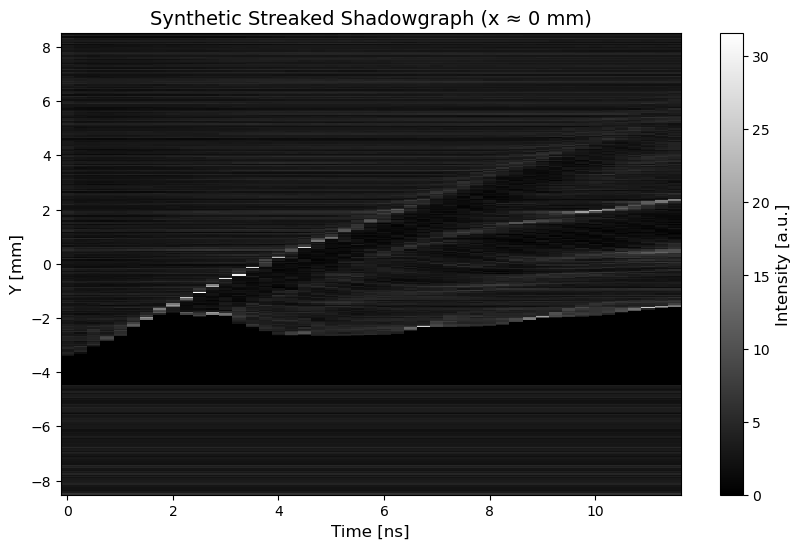

In [12]:
# Sort lineouts chronologically in case file reading was out of order
lineouts.sort(key=lambda d: d["time_ns"])

times = np.array([item["time_ns"] for item in lineouts])
y_coords = lineouts[0]["y_mm"]

# Stack lineouts horizontally: shape becomes (len(y_coords), len(times))
streak_matrix = np.column_stack([item["intensity"] for item in lineouts])

# Plot the Streaked Shadowgraph
fig, ax = plt.subplots(figsize=(10, 6))

# pcolormesh handles non-uniform time steps cleanly
pcm = ax.pcolormesh(times, y_coords, streak_matrix, cmap='gray', shading='auto')

cbar = fig.colorbar(pcm, ax=ax)
cbar.set_label('Intensity [a.u.]', fontsize=12)

ax.set_xlabel('Time [ns]', fontsize=12)
ax.set_ylabel('Y [mm]', fontsize=12)
ax.set_title('Synthetic Streaked Shadowgraph (x ≈ 0 mm)', fontsize=14)

plt.savefig(f'{output_dir}/streaked_shadowgraph.png', dpi=300, bbox_inches='tight')
plt.show()